<a href="https://colab.research.google.com/github/Stephaneno/Stephaneno.github.io/blob/main/Brain_Vs_Lung.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
url = "https://raw.githubusercontent.com/yongmeiwang/AI_BigData_CancerBiology/main/Data/gtex_integrin_7_organs.xlsx"

Gtex_integrin = pd.read_excel(url)
Gtex_integrin.head()

,Unnamed: 0,primary_site,ITGA10,ITGAD,ITGAM,ITGA3,ITGBL1,ITGAE,ITGA2,ITGB3,...,ITGA6,ITGA2B,ITGB1,ITGAL,ITGA9,ITGB5,ITGA8,ITGA4,ITGA1,ITGA11
0,GTEX-13QIC-0011-R1a-SM-5O9CJ,Brain,0.5763,-6.5064,2.2573,0.7832,1.0363,4.6035,2.5731,-2.8262,...,2.8562,1.3846,5.8430,1.1316,-0.7108,3.5387,-0.0725,-0.4521,0.2029,-2.8262
1,GTEX-1399S-1726-SM-5L3DI,Lung,4.9137,-3.6259,4.7307,7.1584,1.7702,4.9556,1.9149,2.6067,...,4.2412,4.1211,7.7256,4.4900,2.9281,6.1483,5.1867,2.6185,4.7856,-0.0277
2,GTEX-PWCY-1326-SM-48TCU,Ovary,2.3953,-5.0116,1.4547,4.2593,-0.7346,4.4149,0.2642,1.5216,...,3.6816,1.5465,7.2964,-0.9406,2.7742,5.0414,2.0325,0.7579,2.2573,1.2516
3,GTEX-QXCU-0626-SM-2TC69,Lung,4.0541,-2.3147,4.5053,7.5651,4.1788,4.1772,5.3695,1.8444,...,4.9631,1.9149,7.9947,3.3911,2.8462,6.7683,4.1636,2.7951,5.3284,1.2147
4,GTEX-ZA64-1526-SM-5CVMD,Breast,2.0569,-2.4659,3.3993,3.1311,3.0074,4.4977,-1.7809,2.7139,...,4.7340,0.6332,7.3496,-0.9406,2.5338,6.5696,1.7229,-0.6416,3.1195,1.1050


In [4]:
Gtex_integrin.shape

(1987, 29)

In [5]:
Gtex_lung_brain=Gtex_integrin[Gtex_integrin["primary_site"].isin(['Lung','Brain'])]
Gtex_lung_brain
Gtex_Lung_Brain_vertical = Gtex_integrin.melt(id_vars = "primary_site", var_name = 'integrin_gene', value_name = 'expression_levels')
Gtex_Lung_Brain_vertical

,primary_site,integrin_gene,expression_levels
0,Brain,Unnamed: 0,GTEX-13QIC-0011-R1a-SM-5O9CJ
1,Lung,Unnamed: 0,GTEX-1399S-1726-SM-5L3DI
2,Ovary,Unnamed: 0,GTEX-PWCY-1326-SM-48TCU
3,Lung,Unnamed: 0,GTEX-QXCU-0626-SM-2TC69
4,Breast,Unnamed: 0,GTEX-ZA64-1526-SM-5CVMD
...,...,...,...
55631,Lung,ITGA11,1.6604
55632,Prostate,ITGA11,0.4233
55633,Breast,ITGA11,1.0151
55634,Brain,ITGA11,-0.5125


In [6]:
%who DataFrame

Gtex_Lung_Brain_vertical	 Gtex_integrin	 Gtex_lung_brain	 


In [7]:
for var in globals():
    if hasattr(globals()[var], 'head'):
        print(var)

RuntimeError: dictionary changed size during iteration

In [8]:
Gtex_Lung_Brain_vertical = pd.melt(
    df,
    id_vars=['Unnamed: 0', 'primary_site'],
    var_name='integrin_gene',
    value_name='expression_levels'
)

NameError: name 'df' is not defined

In [9]:
Gtex_Lung_Brain_vertical = Gtex_Lung_Brain_vertical[
    Gtex_Lung_Brain_vertical['integrin_gene'] != 'Unnamed: 0'
]

In [10]:
Gtex_Lung_Brain_vertical['expression_levels'] = pd.to_numeric(
    Gtex_Lung_Brain_vertical['expression_levels'],
    errors='coerce'
)

/tmp/ipykernel_6572/2040606311.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Gtex_Lung_Brain_vertical['expression_levels'] = pd.to_numeric(


In [11]:
lung_brain = Gtex_Lung_Brain_vertical[
    Gtex_Lung_Brain_vertical['primary_site'].isin(['Brain', 'Lung'])
]

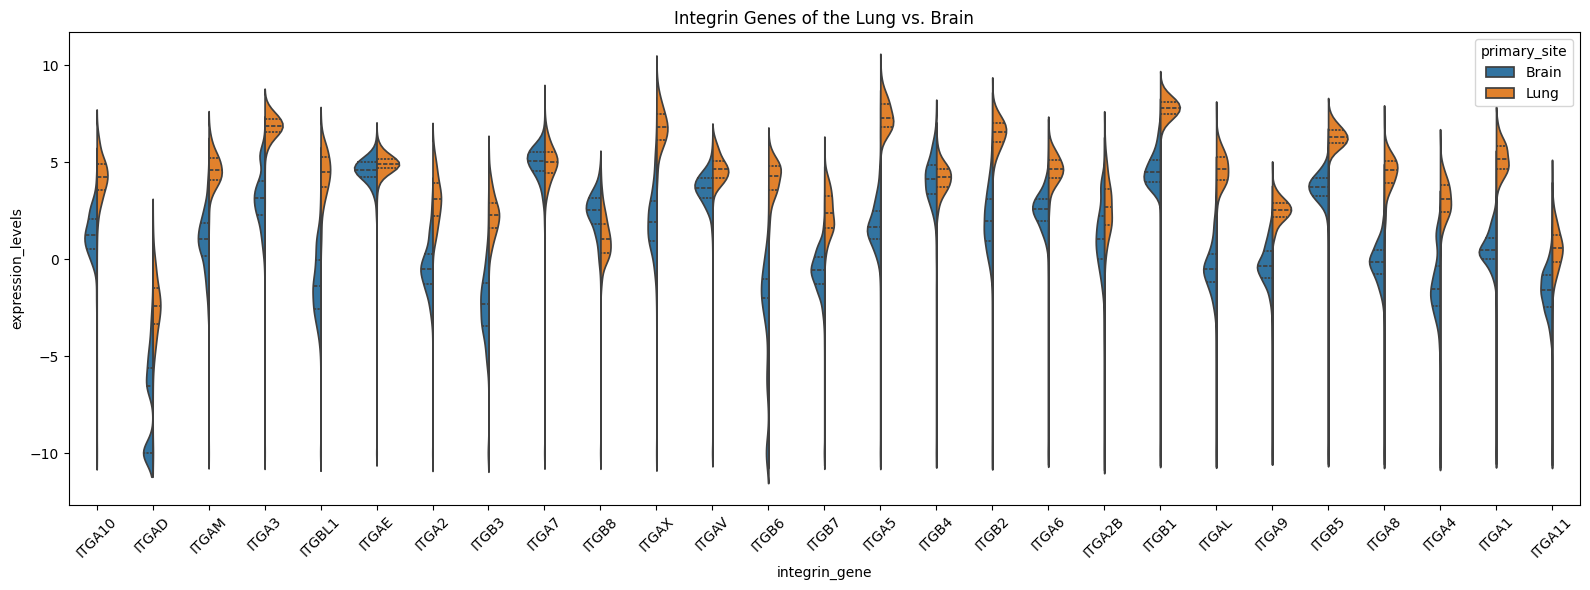

In [12]:
plt.figure(figsize=(16, 6))

sns.violinplot(
    data=lung_brain,
    x='integrin_gene',
    y='expression_levels',
    hue='primary_site',
    split=True,
    inner='quartile'
)

plt.title("Integrin Genes of the Lung vs. Brain")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
print(Gtex_Lung_Brain_vertical.dtypes)
print()
print(Gtex_Lung_Brain_vertical[['integrin_gene',
                                'primary_site',
                                'expression_levels']].head())
print()
print(Gtex_Lung_Brain_vertical['primary_site'].unique())

primary_site          object
integrin_gene         object
expression_levels    float64
dtype: object

     integrin_gene primary_site  expression_levels
1987        ITGA10        Brain             0.5763
1988        ITGA10         Lung             4.9137
1989        ITGA10        Ovary             2.3953
1990        ITGA10         Lung             4.0541
1991        ITGA10       Breast             2.0569

['Brain' 'Lung' 'Ovary' 'Breast' 'Liver' 'Bone Marrow' 'Prostate']


In [14]:
Gtex_lung_brain['primary_site'].value_counts()

,count
primary_site,
Brain,1152
Lung,288


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X = Gtex_lung_brain[['ITGA1']]
y = Gtex_lung_brain['primary_site']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy using ITGA1: {accuracy:.2f}")

Accuracy using ITGA1: 1.00


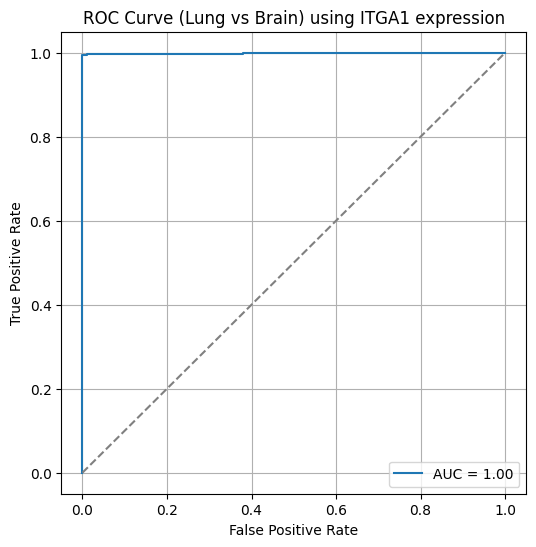

In [17]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

X = Gtex_lung_brain[['ITGA1']]
y = Gtex_lung_brain['primary_site'].map({'Lung': 0, 'Brain': 1})

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

model = LogisticRegression()
model.fit(X_train, y_train)


y_proba = model.predict_proba(X_test)[:, 1]


fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)


plt.figure(figsize = (6, 6))
plt.plot(fpr, tpr, label = f'AUC = {auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle = '--', color = 'gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Lung vs Brain) using ITGA1 expression')
plt.legend()
plt.grid(True)
plt.show()

In [18]:
X = Gtex_lung_brain[['ITGA11']]
y = Gtex_lung_brain['primary_site']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.4, random_state = 42)


model = LogisticRegression()
model.fit(X_train, y_train)


y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test,y_pred)
print(f"Accuracy using ITGA11: {accuracy:.2f}")


Accuracy using ITGA11: 0.89


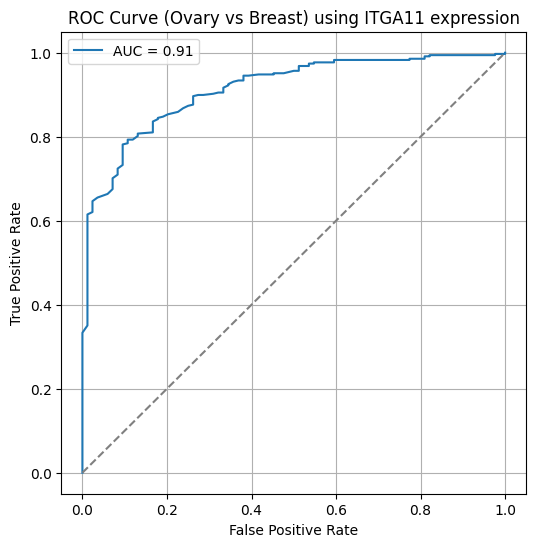

In [20]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

X = Gtex_lung_brain[['ITGA11']]
y = Gtex_lung_brain['primary_site'].map({'Lung': 0, 'Brain': 1})

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

model = LogisticRegression()
model.fit(X_train, y_train)


y_proba = model.predict_proba(X_test)[:, 1]


fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

#plot
plt.figure(figsize = (6, 6))
plt.plot(fpr, tpr, label = f'AUC = {auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle = '--', color = 'gray')  # random guess line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Ovary vs Breast) using ITGA11 expression')
plt.legend()
plt.grid(True)
plt.show()

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


selected_genes = ['ITGA1', 'ITGA11']
X = Gtex_integrin[selected_genes]
y = Gtex_integrin['primary_site']

#encode organ labels as numbers
le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size = 0.2, random_state = 42)

model = LogisticRegression(solver = 'lbfgs', max_iter = 1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names = le.classes_))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8618090452261307

Classification Report:
              precision    recall  f1-score   support

 Bone Marrow       0.78      0.70      0.74        10
       Brain       0.96      0.98      0.97       247
      Breast       0.65      0.55      0.59        44
       Liver       0.95      0.83      0.88        23
        Lung       0.70      0.93      0.80        43
       Ovary       0.38      0.50      0.43        10
    Prostate       0.58      0.33      0.42        21

    accuracy                           0.86       398
   macro avg       0.72      0.69      0.69       398
weighted avg       0.86      0.86      0.86       398


Confusion Matrix:
[[  7   3   0   0   0   0   0]
 [  2 241   1   0   0   3   0]
 [  0   3  24   0   9   4   4]
 [  0   0   0  19   4   0   0]
 [  0   0   2   1  40   0   0]
 [  0   3   1   0   0   5   1]
 [  0   0   9   0   4   1   7]]


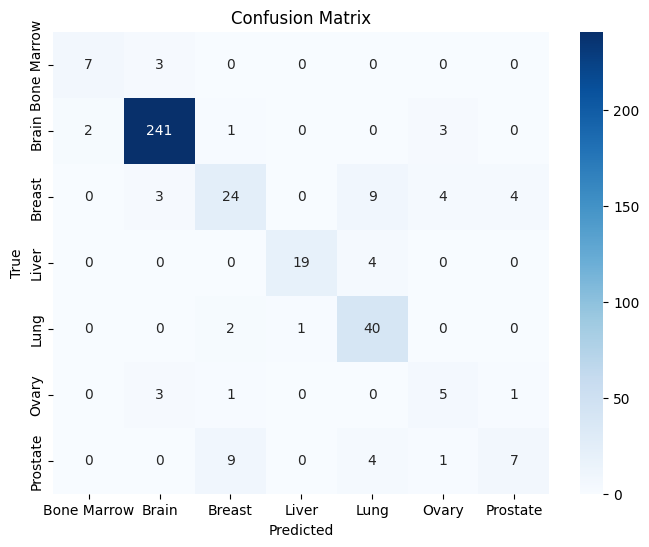

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize = (8, 6))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues',
            xticklabels = le.classes_, yticklabels = le.classes_)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()